# COVID-19 CT Classifier: patient-separated split

The original notebook (`classifier.ipynb`) reached **99.76% test accuracy**, but it split the slices at random. The dataset has about 19,700 slices from only about 100 patients, and neighbouring slices of one scan look almost identical, so the same patients ended up in both training and test.

This notebook splits the data **by patient**: all slices of a patient go into the same split, so the test set contains only patients the model has never seen. The model is the same as in the original notebook (MobileNetV3-Large).

The filenames don't contain patient IDs. The patient groups come from the audit in `audit/` (steps 1 to 5), which rebuilt the scans from image similarity and joined them into groups. The result is `outputs/audit/patient_groups.csv`, with one `group_id` per slice.

> The groups are reconstructed, not official patient IDs. A group can contain two patients (harmless: they stay on the same side), and a few patients may still be split across groups, mostly slices above or below the lungs. So the result here is a much fairer estimate than the random split, but not a perfect one.

**Run history**

- **Run 1** (log saved in `outputs/patient_split/run1_baseline.ipynb`): the original training settings, with only the split changed. Validation 93.60%, test 96.49%. Training loss fell to about 0.03 while validation loss jumped between 0.08 and 0.63 from one check to the next, and the model saved was the one from the last epoch, not the best one.
- **Run 2** (this version): settings changed to reduce overfitting and the jumping. See *Settings*.

> This is a learning project, not a medical tool.

## Imports

In [1]:
%matplotlib inline

import copy
import csv
import random
import time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

## Settings

Changes from run 1, which used the original notebook's settings:

| setting | run 1 | run 2 | why |
|---|---|---|---|
| epochs | 25 | 15 | training loss was already flat by about epoch 15 |
| learning rate | 1e-4, constant | 1e-4, cosine decay to 1e-6 | a constant rate kept the weights jumping between epochs |
| weight decay | 1e-4 | 0.05 | 1e-4 has almost no effect with AdamW |
| label smoothing | none | 0.1 | stops the model from becoming overconfident on the training patients |
| augmentation | random crop (8–100% of the image), flip | crop of 60–100%, flip, small rotation, brightness/contrast | small crops could cut away the lungs |
| model kept | last epoch | epoch with the lowest validation loss | |
| validation | every 200 steps | once per epoch | the extra passes slowed training and don't change it |

`SMOKE_TEST = True` trains for one epoch to check that everything works.

In [2]:
DATA_ROOT      = Path("dataset") / "Original CT Scans"   # contains the nCT, NiCT and pCT folders
GROUPS_CSV     = Path("outputs") / "audit" / "patient_groups.csv"
OUTPUT_DIR     = Path("outputs") / "patient_split"
CHECKPOINT_DIR = Path("outputs") / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE      = 16
IMG_SHAPE       = 224
EPOCHS          = 15
MODEL_NAME      = "mobilenet_v3_large"
FINE_TUNING     = True
LEARN_RATE      = 1e-4
MIN_LEARN_RATE  = 1e-6   # the cosine schedule ends here
WEIGHT_DECAY    = 0.05
LABEL_SMOOTHING = 0.1
CROP_SCALE      = (0.6, 1.0)   # random crops keep 60-100% of the image
ROTATION_DEG    = 10
RUN_NAME        = "run2"

SPLIT_SEED = 42
VAL_FRAC   = 0.15
TEST_FRAC  = 0.15

SMOKE_TEST = False  # set to True to run a single epoch for testing the code
if SMOKE_TEST:
    EPOCHS = 1

# NVIDIA GPU, then Apple GPU, otherwise CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

USE_AMP     = False
NUM_WORKERS = 4                      # set to 0 if the DataLoader hangs on Windows
PIN_MEMORY  = device.type == "cuda"

torch.manual_seed(SPLIT_SEED)
print(f"PyTorch {torch.__version__} | device: {device} | epochs: {EPOCHS}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch 2.14.1+cu130 | device: cuda | epochs: 15
GPU: NVIDIA GeForce GTX 1650


## Patient groups

Every image gets the `group_id` from the audit. The check makes sure that every image in the dataset has a group and no group is missing an image.

In [3]:
base = datasets.ImageFolder(DATA_ROOT)
classes = base.classes
print("Classes:", classes, "| images:", len(base))

group_of_file = {}
with open(GROUPS_CSV) as f:
    for r in csv.DictReader(f):
        group_of_file[(r["cls"], r["file"])] = r["group_id"]

sample_group = []
for path, y in base.samples:
    key = (classes[y], Path(path).name)
    assert key in group_of_file, f"No group for {key}; rerun the audit steps"
    sample_group.append(group_of_file[key])
assert len(group_of_file) == len(base.samples)

samples_of_group = defaultdict(list)
for i, g in enumerate(sample_group):
    samples_of_group[g].append(i)

# A group is a COVID patient if it has any pCT slice
pct = classes.index("pCT")
group_kind = {g: "covid" if any(base.samples[i][1] == pct for i in idx) else "non-covid"
              for g, idx in samples_of_group.items()}

print(f"{len(samples_of_group)} groups:", dict(Counter(group_kind.values())))

Classes: ['NiCT', 'nCT', 'pCT'] | images: 19685
167 groups: {'non-covid': 132, 'covid': 35}


## Split by patient group

COVID and non-COVID groups are split separately, so both kinds appear in every split. Within each kind the groups are shuffled with a fixed seed and assigned to test, then validation, then training, until each split has about its share of the slices. A group is never divided between splits.

In [4]:
rng = random.Random(SPLIT_SEED)
split_of_group = {}
for kind in ["covid", "non-covid"]:
    gids = sorted(g for g in samples_of_group if group_kind[g] == kind)
    rng.shuffle(gids)
    total = sum(len(samples_of_group[g]) for g in gids)
    done = 0
    for g in gids:
        frac = done / total
        if frac < TEST_FRAC:
            split_of_group[g] = "test"
        elif frac < TEST_FRAC + VAL_FRAC:
            split_of_group[g] = "valid"
        else:
            split_of_group[g] = "train"
        done += len(samples_of_group[g])

split_idx = {"train": [], "valid": [], "test": []}
for g, idx in samples_of_group.items():
    split_idx[split_of_group[g]] += idx
train_idx, val_idx, test_idx = (sorted(split_idx[s]) for s in ["train", "valid", "test"])

# No group may appear in two splits
groups_in = {s: {sample_group[i] for i in split_idx[s]} for s in split_idx}
assert not (groups_in["train"] & groups_in["valid"])
assert not (groups_in["train"] & groups_in["test"])
assert not (groups_in["valid"] & groups_in["test"])

print(f"{'split':6s} {'groups':>7s} {'covid grp':>10s} " + " ".join(f"{c:>6s}" for c in classes) + "   total")
for s in ["train", "valid", "test"]:
    counts = Counter(classes[base.samples[i][1]] for i in split_idx[s])
    n_cov = sum(group_kind[g] == "covid" for g in groups_in[s])
    print(f"{s:6s} {len(groups_in[s]):7d} {n_cov:10d} " + " ".join(f"{counts[c]:6d}" for c in classes)
          + f"  {len(split_idx[s]):6d}")

# Save the split so the result can be reproduced and checked
with open(OUTPUT_DIR / "split.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["file", "cls", "group_id", "split"])
    for i, (path, y) in enumerate(base.samples):
        w.writerow([Path(path).name, classes[y], sample_group[i], split_of_group[sample_group[i]]])

split   groups  covid grp   NiCT    nCT    pCT   total
train      130         23   3714   7274   2619   13607
valid       18          7   1081   1242    739    3062
test        19          5    910   1463    643    3016


## Loading the data

Training images get random crops (keeping 60–100% of the image), flips, small rotations and small brightness/contrast changes. Validation and test use a fixed center crop, as in the original notebook.

In [5]:
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
data_transforms = {
    "train": transforms.Compose([
        transforms.Resize(256),
        transforms.RandomResizedCrop(IMG_SHAPE, scale=CROP_SCALE),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(ROTATION_DEG),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        normalize,
    ]),
    "valid": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SHAPE),
        transforms.ToTensor(),
        normalize,
    ]),
}

train_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms["train"]), train_idx)
val_ds   = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms["valid"]), val_idx)
test_ds  = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms["valid"]), test_idx)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
                     persistent_workers=NUM_WORKERS > 0)
dataloaders = {
    "train": DataLoader(train_ds, shuffle=True,  **loader_kwargs),
    "valid": DataLoader(val_ds,   shuffle=False, **loader_kwargs),
    "test":  DataLoader(test_ds,  shuffle=False, **loader_kwargs),
}

xb, yb = next(iter(dataloaders["train"]))
print("Batch:", xb.shape, yb.shape)

Batch: torch.Size([16, 3, 224, 224]) torch.Size([16])


## The model

Identical to the original: MobileNetV3-Large pretrained on ImageNet, with its last layers replaced by 960 → 1,280 (ReLU + 20% dropout) → 3 classes and a log-softmax.

The loss is cross-entropy with label smoothing: the target for the true class is 0.9 instead of 1, with the rest spread over the other classes. The model outputs log-probabilities, and `CrossEntropyLoss` applied to log-probabilities gives the same result as `NLLLoss`, so only the smoothing is new. The learning rate follows a cosine curve from 1e-4 down to 1e-6 over the whole run, updated after every batch.

In [6]:
class Classifier(nn.Module):
    def __init__(self, input_size, output_size, hidden_layers=(1280,), drop_p=0.2):
        super().__init__()
        layers, prev = [], input_size
        for h in hidden_layers:
            layers += [nn.Linear(prev, h), nn.ReLU(inplace=True), nn.Dropout(p=drop_p)]
            prev = h
        layers.append(nn.Linear(prev, output_size))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return F.log_softmax(self.net(x), dim=1)


model = models.mobilenet_v3_large(weights="DEFAULT")
if not FINE_TUNING:
    for p in model.features.parameters():
        p.requires_grad = False
model.classifier = Classifier(960, len(classes), hidden_layers=[1280], drop_p=0.2)
model = model.to(device)

# log_softmax of log-probabilities leaves them unchanged, so this equals NLLLoss plus smoothing
train_criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
criterion = nn.NLLLoss()   # plain loss for validation and test, comparable with run 1
optimizer = optim.AdamW((p for p in model.parameters() if p.requires_grad),
                        lr=LEARN_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS * len(dataloaders["train"]), eta_min=MIN_LEARN_RATE)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Trainable parameters: 4,205,875


## Training

After every epoch the model is checked on the validation set. The weights from the epoch with the lowest validation loss are kept, and put back into the model at the end, so the results below come from the best epoch, not the last one.

In [7]:
def format_duration(seconds):
    m, s = divmod(int(round(seconds)), 60)
    h, m = divmod(m, 60)
    return f"{h}h{m:02d}m{s:02d}s" if h else f"{m}m{s:02d}s"


def predict_all(model, loader):
    # Return predicted classes, true classes and the average loss for one split
    model.eval()
    preds, labels, loss_sum = [], [], 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss_sum += criterion(out, y).item() * y.size(0)
            preds.append(out.argmax(dim=1).cpu())
            labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return preds, labels, loss_sum / len(labels)


def evaluate(model, loader):
    preds, labels, loss = predict_all(model, loader)
    return loss, float((preds == labels).mean())


def training(model, trainloader, validloader, epochs, use_amp=False):
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best = {"val_loss": float("inf"), "epoch": 0, "state_dict": None}
    t_start = time.perf_counter()
    for e in range(1, epochs + 1):
        t_epoch = time.perf_counter()
        model.train()
        running = 0.0
        for x, y in trainloader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                loss = train_criterion(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
        train_loss = running / len(trainloader)
        val_loss, val_acc = evaluate(model, validloader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        mark = ""
        if val_loss < best["val_loss"]:
            best = {"val_loss": val_loss, "epoch": e, "state_dict": copy.deepcopy(model.state_dict())}
            mark = "  * best so far"
        eta = (time.perf_counter() - t_start) / e * (epochs - e)
        print(f"Epoch {e}/{epochs}  TrainLoss {train_loss:.4f}  ValLoss {val_loss:.4f}  ValAcc {val_acc:.4f}  "
              f"LR {scheduler.get_last_lr()[0]:.1e}  | took {format_duration(time.perf_counter() - t_epoch)}, "
              f"about {format_duration(eta)} left{mark}")
    print(f"Training finished in {format_duration(time.perf_counter() - t_start)}")
    model.load_state_dict(best["state_dict"])
    print(f"Kept the weights from epoch {best['epoch']} (validation loss {best['val_loss']:.4f})")
    history["best_epoch"] = best["epoch"]
    return history

In [8]:
history = training(model, dataloaders["train"], dataloaders["valid"], EPOCHS, use_amp=USE_AMP)

Epoch 1/15  TrainLoss 0.3730  ValLoss 0.2193  ValAcc 0.9484  LR 9.9e-05  | took 2m03s, about 28m41s left  * best so far
Epoch 2/15  TrainLoss 0.3217  ValLoss 0.1493  ValAcc 0.9749  LR 9.6e-05  | took 1m25s, about 22m29s left  * best so far
Epoch 3/15  TrainLoss 0.3105  ValLoss 0.2485  ValAcc 0.9213  LR 9.1e-05  | took 1m31s, about 19m53s left
Epoch 4/15  TrainLoss 0.3086  ValLoss 0.2119  ValAcc 0.9419  LR 8.4e-05  | took 1m28s, about 17m43s left
Epoch 5/15  TrainLoss 0.3053  ValLoss 0.1366  ValAcc 0.9778  LR 7.5e-05  | took 2m08s, about 17m09s left  * best so far
Epoch 6/15  TrainLoss 0.3029  ValLoss 0.2643  ValAcc 0.9190  LR 6.6e-05  | took 4m26s, about 19m31s left
Epoch 7/15  TrainLoss 0.3017  ValLoss 0.2118  ValAcc 0.9379  LR 5.6e-05  | took 4m29s, about 20m00s left
Epoch 8/15  TrainLoss 0.2992  ValLoss 0.1246  ValAcc 0.9843  LR 4.5e-05  | took 4m32s, about 19m17s left  * best so far
Epoch 9/15  TrainLoss 0.2991  ValLoss 0.2794  ValAcc 0.9095  LR 3.5e-05  | took 4m25s, about 17m38s 

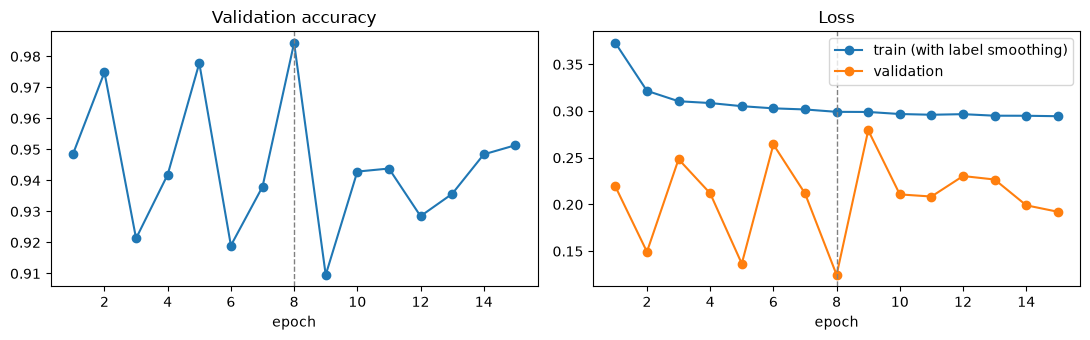

In [9]:
if len(history["val_acc"]) > 1:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ep = range(1, len(history["val_acc"]) + 1)
    a1.plot(ep, history["val_acc"], marker="o"); a1.set_title("Validation accuracy"); a1.set_xlabel("epoch")
    a2.plot(ep, history["train_loss"], marker="o", label="train (with label smoothing)")
    a2.plot(ep, history["val_loss"], marker="o", label="validation")
    a2.set_title("Loss"); a2.set_xlabel("epoch"); a2.legend()
    for a in (a1, a2):
        a.axvline(history["best_epoch"], color="grey", linestyle="--", linewidth=1)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"training_curves_{RUN_NAME}.png", dpi=150)
    plt.show()

## Results

First the overall accuracy, to compare with the 99.76% from the random split. Then the confusion matrix and per-class recall, because overall accuracy hides which mistakes the model makes. For a COVID classifier the most important number is the recall of `pCT`: how many COVID slices it catches.

In [10]:
results = {}
for s in ["valid", "test"]:
    results[s] = predict_all(model, dataloaders[s])
    preds, labels, loss = results[s]
    print(f"{s:5s}: accuracy {np.mean(preds == labels):.2%}, loss {loss:.4f}, slices {len(labels)}")
print("\nRun 1 (original settings):              valid 93.60%, test 96.49%")
print("Random slice split (original notebook): test accuracy 99.76%")

valid: accuracy 98.43%, loss 0.1246, slices 3062
test : accuracy 98.28%, loss 0.1201, slices 3016

Run 1 (original settings):              valid 93.60%, test 96.49%
Random slice split (original notebook): test accuracy 99.76%


Per-class results on the test set:
  NiCT  recall 97.69%  precision 97.26%  (910 slices)
  nCT   recall 98.91%  precision 98.57%  (1463 slices)
  pCT   recall 97.67%  precision 99.05%  (643 slices)


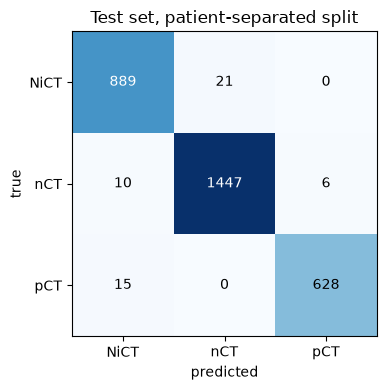

In [11]:
preds, labels, _ = results["test"]
n_cls = len(classes)
cm = np.zeros((n_cls, n_cls), dtype=int)
for t, p in zip(labels, preds):
    cm[t, p] += 1

print("Per-class results on the test set:")
for k, c in enumerate(classes):
    recall = cm[k, k] / cm[k].sum() if cm[k].sum() else float("nan")
    precision = cm[k, k] / cm[:, k].sum() if cm[:, k].sum() else float("nan")
    print(f"  {c:5s} recall {recall:.2%}  precision {precision:.2%}  ({cm[k].sum()} slices)")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(n_cls):
    for j in range(n_cls):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(n_cls), classes); ax.set_yticks(range(n_cls), classes)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Test set, patient-separated split")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"confusion_matrix_{RUN_NAME}.png", dpi=150)
plt.show()

### Results per patient group

The test set has only a handful of patient groups, so a single difficult patient can move the overall accuracy a lot. This table shows the accuracy within each test group, worst first. It's a first look at patient-level behaviour; proper whole-scan predictions are the next stage.

In [12]:
test_group = [sample_group[i] for i in test_idx]
per_group = defaultdict(lambda: [0, 0])
for g, t, p in zip(test_group, labels, preds):
    per_group[g][0] += int(t == p)
    per_group[g][1] += 1

print(f"{'group':6s} {'kind':10s} {'slices':>6s} {'accuracy':>9s}")
for g, (ok, n) in sorted(per_group.items(), key=lambda kv: kv[1][0] / kv[1][1]):
    print(f"{g:6s} {group_kind[g]:10s} {n:6d} {ok / n:9.2%}")

group  kind       slices  accuracy
G031   covid         207    94.20%
G020   non-covid     226    94.69%
G007   non-covid     305    96.72%
G002   non-covid     806    98.14%
G040   covid         172    98.26%
G105   non-covid      62   100.00%
G075   non-covid      98   100.00%
G132   non-covid      33   100.00%
G160   non-covid      14   100.00%
G122   non-covid      44   100.00%
G155   non-covid      18   100.00%
G018   non-covid     235   100.00%
G041   non-covid     169   100.00%
G056   non-covid     129   100.00%
G074   non-covid     101   100.00%
G096   non-covid      70   100.00%
G046   covid         147   100.00%
G060   covid         117   100.00%
G104   covid          63   100.00%


## Saving the model

In [13]:
checkpoint = {
    "arch": MODEL_NAME,
    "input_size": 960,
    "output_size": len(classes),
    "hidden_layers": [1280],
    "drop_p": 0.2,
    "img_shape": IMG_SHAPE,
    "class_to_idx": base.class_to_idx,
    "classes": classes,
    "split": "patient groups (outputs/patient_split/split.csv)",
    "settings": {"epochs": EPOCHS, "best_epoch": history["best_epoch"], "lr": LEARN_RATE,
                 "min_lr": MIN_LEARN_RATE, "weight_decay": WEIGHT_DECAY,
                 "label_smoothing": LABEL_SMOOTHING, "crop_scale": CROP_SCALE,
                 "rotation_deg": ROTATION_DEG},
    "state_dict": model.state_dict(),
}
suffix = "_smoke" if SMOKE_TEST else ""
filepath = CHECKPOINT_DIR / f"{MODEL_NAME}_patient_split_{RUN_NAME}{suffix}.pth"
torch.save(checkpoint, filepath)
print("Saved", filepath)

Saved outputs\checkpoints\mobilenet_v3_large_patient_split_run2.pth


## Trying the model on your own image

This cell loads the saved model and classifies CT slices you upload. It only needs the *Imports* cell, so after a restart you can run it without training again. Upload one or more images (JPG or PNG; DICOM files are not supported) with the button. To use a file on disk instead, set `IMAGE_PATH`.

The model expects the same kind of image it was trained on: one axial chest CT slice, as in the dataset. The answer is one of:

- `pCT`: signs of COVID-19 in the lungs
- `nCT`: lungs visible, no signs of COVID-19
- `NiCT`: not enough of the lungs visible to judge. Try a slice through the middle of the chest.

> The model has only seen scans from two hospitals in Wuhan. Images from other scanners or hospitals may look different, and it has not been tested on them. One slice is not a diagnosis.

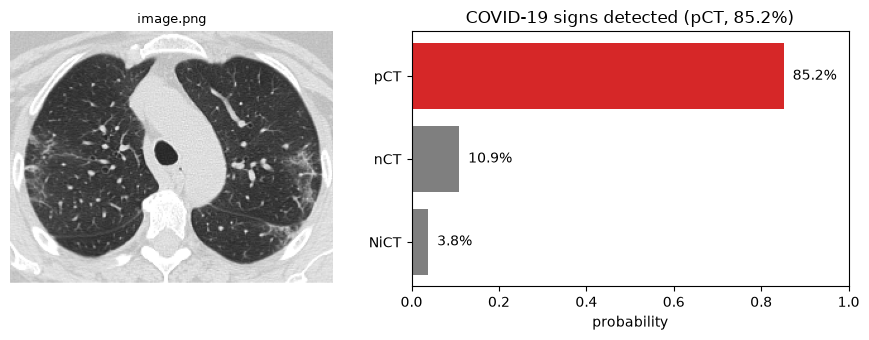

FileUpload(value=(), accept='image/*', description='Upload CT slice', multiple=True)

Output()

In [14]:
import io
from collections import OrderedDict

import ipywidgets as widgets
from IPython.display import display
from PIL import Image

INFER_CHECKPOINT = Path("outputs") / "checkpoints" / "mobilenet_v3_large_patient_split_run2.pth"
IMAGE_PATH = Path("inference_images/image.png")   

VERDICT = {
    "pCT":  "COVID-19 signs detected",
    "nCT":  "No COVID-19 signs",
    "NiCT": "Not enough lung visible to judge",
}


def load_model(path):
    ckpt = torch.load(path, map_location="cpu")
    layers, prev = [], ckpt["input_size"]
    for h in ckpt["hidden_layers"]:
        layers += [nn.Linear(prev, h), nn.ReLU(inplace=True), nn.Dropout(p=ckpt["drop_p"])]
        prev = h
    layers.append(nn.Linear(prev, ckpt["output_size"]))
    net = models.mobilenet_v3_large(weights=None)
    # Same parameter names as the Classifier above (classifier.net.*); returns logits instead of log-probabilities
    net.classifier = nn.Sequential(OrderedDict(net=nn.Sequential(*layers)))
    net.load_state_dict(ckpt["state_dict"])
    net.eval()
    names = sorted(ckpt["class_to_idx"], key=ckpt["class_to_idx"].get)
    return net, names, ckpt["img_shape"]


infer_model, infer_classes, infer_size = load_model(INFER_CHECKPOINT)
infer_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(infer_size),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


def to_rgb(img):
    # 16-bit PNGs would be clipped by convert("RGB"), so scale them to 8 bit first
    if img.mode in ("I", "I;16", "I;16B", "F"):
        a = np.asarray(img, dtype=np.float32)
        a = (a - a.min()) / max(a.max() - a.min(), 1e-6) * 255
        img = Image.fromarray(a.astype(np.uint8))
    return img.convert("RGB")


def classify(img, title=""):
    img = to_rgb(img)
    with torch.no_grad():
        probs = torch.softmax(infer_model(infer_transform(img).unsqueeze(0)), dim=1)[0].numpy()
    best = infer_classes[int(probs.argmax())]

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.5), gridspec_kw={"width_ratios": [1, 1.2]})
    a1.imshow(img); a1.axis("off"); a1.set_title(title, fontsize=9)
    colors = ["tab:red" if c == "pCT" else "tab:grey" for c in infer_classes]
    a2.barh(infer_classes, probs, color=colors)
    a2.set_xlim(0, 1); a2.set_xlabel("probability")
    for i, p in enumerate(probs):
        a2.text(min(p + 0.02, 0.9), i, f"{p:.1%}", va="center")
    a2.set_title(f"{VERDICT[best]} ({best}, {probs.max():.1%})")
    plt.tight_layout()
    plt.show()


if IMAGE_PATH is not None:
    classify(Image.open(IMAGE_PATH), Path(IMAGE_PATH).name)

upload = widgets.FileUpload(accept="image/*", multiple=True, description="Upload CT slice")
upload_out = widgets.Output()


def on_upload(change):
    with upload_out:
        upload_out.clear_output()
        for f in change["new"]:
            classify(Image.open(io.BytesIO(f["content"])), f["name"])


upload.observe(on_upload, names="value")
display(upload, upload_out)